<a href="https://colab.research.google.com/github/rubendrt42-eng/SQL-Analitica-Ruben/blob/main/Etapa3_OT/Etapa3_Limpieza_OT_Equipo1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Etapa 3 · Limpieza y preparación de los datos de OT Consulting

**Equipo 1** · Soporte analítico para la toma de decisiones (TI2006B, Gpo 301) · noviembre 2026

- Rubén David Rodríguez Treviño · A01198984
- Erika Esquivel Correa · A00841206
- Iván Fundora Velasco · A01198822
- Julen Benages Díaz · A01832758

En la etapa 2 revisamos los datos de la app de OT y encontramos de todo: fechas de relleno, gente sin puesto, bajas que siguen con sueldo y, lo más grave, que no hay nada del dinero de los proyectos. En este notebook los arreglamos. La meta es terminar con **una sola tabla limpia** que se pueda conectar a Tableau para el tablero del director.

Algo que tuvimos claro desde el principio es que no todo se arregla con código. Hay cosas que **corregimos**, cosas que **eliminamos**, cosas que **estimamos** con lo que nos dijo OT y cosas que solo podemos **marcar** porque nada más OT puede capturarlas. Cada arreglo lo vamos anotando en una bitácora, y al final revisamos si de verdad quedó limpio.

## 1. Cargo los datos

Son los mismos 11 CSV que sacamos de la app para la etapa 2, con corte al 16 de noviembre. Si abres esto en Colab, te va a pedir que subas `datos_ot.zip`.

Leemos todo como texto para que pandas no nos cambie los IDs, y solo convertimos a número las columnas que sí son números. Guardamos una copia sin tocar (`crudo`) para comparar al final.

In [1]:
import os, zipfile, sqlite3, warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 220)
pd.set_option('display.max_colwidth', 50)

CARPETA = 'datos_ot'
if not os.path.isdir(CARPETA):          # en Colab: subir datos_ot.zip
    from google.colab import files
    print('Sube el archivo datos_ot.zip')
    subidos = files.upload()
    os.makedirs(CARPETA, exist_ok=True)
    for nombre in subidos:
        if nombre.endswith('.zip'):
            zipfile.ZipFile(nombre).extractall('.')
        elif nombre.endswith('.csv'):
            os.replace(nombre, os.path.join(CARPETA, nombre))

ARCHIVOS = ['colaboradores', 'roles', 'departamentos', 'habilidades', 'matriz_habilidades',
            'clientes', 'proyectos', 'asignaciones', 'activos', 'activos_asignaciones', 'usuarios']
NUMERICAS = {
    'colaboradores': ['sueldo_imss', 'sueldo_asimilados', 'sueldo_complementos', 'sueldo_neto_total',
                      'comision_nomina', 'impuestos_imss', 'sueldo_total_integrado', 'tiene_rfc', 'tiene_curp',
                      'tiene_nss', 'tiene_email', 'tiene_telefono', 'docs_cargados', 'n_anexos'],
    'roles': ['desc_igual_nombre'],
    'clientes': ['n_proyectos'],
    'activos': ['costo', 'tiene_serie', 'n_asig'],
    'activos_asignaciones': ['tiene_notas'],
}

crudo = {}
for a in ARCHIVOS:
    t = pd.read_csv(f'{CARPETA}/{a}.csv', dtype=str, keep_default_na=False).replace({'': np.nan})
    for c in NUMERICAS.get(a, []):
        t[c] = pd.to_numeric(t[c], errors='coerce')
    crudo[a] = t

df = {a: t.copy() for a, t in crudo.items()}   # sobre esta copia hacemos todos los arreglos
pd.DataFrame([{'archivo': f'{a}.csv', 'renglones': len(t), 'columnas': t.shape[1]} for a, t in crudo.items()])

,archivo,renglones,columnas
0,colaboradores.csv,107,30
1,roles.csv,55,7
2,departamentos.csv,6,7
3,habilidades.csv,71,6
4,matriz_habilidades.csv,1539,3
5,clientes.csv,8,15
6,proyectos.csv,12,10
7,asignaciones.csv,31,7
8,activos.csv,123,13
9,activos_asignaciones.csv,91,5


## 2. Nuestras reglas antes de empezar

Estos son los números que usamos en todo el notebook. Los primeros los dijo OT en la entrevista. Los de abajo son supuestos nuestros: los dejamos aquí arriba para que se vean y se puedan cambiar fácil si OT nos da el dato real.

El tipo de cambio es el FIX de Banxico del 13 de noviembre de 2026 (18.5525), que es el último publicado antes del corte de los datos. Lo redondeamos a 18.55.

In [2]:
FECHA_CORTE = pd.Timestamp('2026-11-16')    # día en que sacamos los datos de la app
FECHA_MINIMA = pd.Timestamp('2000-01-01')   # OT empezó como negocio en el 2000; antes no puede haber nada

# Reglas que nos dio OT
HORAS_MES = 176                 # 22 días x 8 horas
CARGA_ADMIN = 0.20              # 20% de costo administrativo encima del sueldo integrado
META_MARGEN = (0.20, 0.30)      # margen objetivo SOBRE EL COSTO

# Supuestos nuestros (cámbialos si OT da el dato real)
TARIFAS_USD = [40, 45, 50]      # el director dijo que hoy cobran entre 40 y 50 USD por hora
TIPO_CAMBIO = 18.55             # FIX Banxico, 13 nov 2026
DEDICACION_CONSULTOR = 1.00     # OT: un consultor normalmente está en un solo proyecto
DEDICACION_GERENTE = 0.25       # OT: un gerente reparte entre 20 y 30% de su tiempo en cada proyecto
FACTURABLES = ['Consultor', 'Consultor (inferido)', 'Gerente de proyectos']

# Bitácora: cada arreglo que hacemos queda anotado aquí
bitacora = []
def anota(tabla, problema, que_hice, resultado, registros):
    bitacora.append({'tabla': tabla, 'problema': problema, 'qué hicimos': que_hice,
                     'resultado': resultado, 'registros': int(registros)})
    print(f'[{resultado}] {tabla}: {problema} -> {int(registros)}')

# colores de las gráficas (los mismos de la etapa 2)
AZUL, GRIS_BARRA, ROJO = '#2a78d6', '#c3c2b7', '#d03b3b'
TINTA, TINTA2, GRIS, FONDO = '#0b0b0b', '#52514e', '#e1e0d9', '#fcfcfb'
plt.rcParams.update({
    'figure.facecolor': FONDO, 'axes.facecolor': FONDO, 'savefig.facecolor': FONDO,
    'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.edgecolor': GRIS_BARRA, 'axes.labelcolor': TINTA2, 'text.color': TINTA,
    'xtick.color': TINTA2, 'ytick.color': TINTA2,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
})

## 3. Lo que aplica a todas las tablas

Antes de ir tabla por tabla hicimos dos limpiezas generales.

**Espacios de más.** Para la computadora, "Grupo Daltile " (con espacio al final) y "Grupo Daltile" son dos clientes distintos. Les quitamos los espacios del principio, del final y los dobles a todos los textos.

**Fechas.** Las pasamos de texto a fecha. Cualquier fecha antes del 2000 la tomamos como vacía, porque OT empezó como negocio en el 2000 (y se formalizó en 2003), así que es imposible que tenga algo antes. Con esta regla caen el 1990-01-01 que usaban de relleno y el 0199-01-01 que encontramos en los equipos. Preferimos una fecha vacía que una fecha falsa: una vacía se ve que falta, una falsa te engaña.

In [3]:
def limpia_texto(t):
    cambios = 0
    for c in t.columns:
        s = t[c]
        if pd.api.types.is_numeric_dtype(s):
            continue
        nueva = s.where(s.isna(), s.astype(str).str.strip().str.replace(r'\s+', ' ', regex=True))
        cambios += int((nueva.fillna('') != s.fillna('')).sum())
        t[c] = nueva
    return cambios

total_espacios = 0
for a, t in df.items():
    n = limpia_texto(t)
    total_espacios += n
    if n:
        print(f'  {a}: {n} celdas')
anota('todas', 'textos con espacios de más', 'quitar espacios al inicio, al final y dobles', 'Corregido', total_espacios)

  roles: 1 celdas
  departamentos: 4 celdas
  habilidades: 2 celdas
  clientes: 13 celdas
  proyectos: 8 celdas
  asignaciones: 5 celdas
  activos: 16 celdas
[Corregido] todas: textos con espacios de más -> 49


In [4]:
FECHAS = {'colaboradores': ['fechainc', 'fechabaja'], 'proyectos': ['inicio', 'fin'],
          'asignaciones': ['inicio', 'fin'], 'activos': ['fcompra', 'fgarantia'],
          'activos_asignaciones': ['f_ini', 'f_fin']}

fecha_mala = {}      # guardamos qué fechas eran de relleno para marcarlas después
for a, columnas in FECHAS.items():
    for c in columnas:
        texto = df[a][c]
        f = pd.to_datetime(texto, errors='coerce', format='%Y-%m-%d')
        mala = texto.notna() & (f.isna() | (f < FECHA_MINIMA))
        fecha_mala[(a, c)] = mala
        df[a][c] = f.where(~mala)
        if mala.any():
            print(f'  {a}.{c}: {mala.sum()} fechas de relleno o imposibles ->', sorted(texto[mala].unique()))

total_fechas = sum(m.sum() for m in fecha_mala.values())
anota('todas', 'fechas de relleno o imposibles (antes del 2000)', 'se dejan vacías y se marcan', 'Corregido', total_fechas)

  asignaciones.inicio: 21 fechas de relleno o imposibles -> ['1990-01-01']
  activos_asignaciones.f_ini: 36 fechas de relleno o imposibles -> ['0199-01-01', '1990-01-01']
[Corregido] todas: fechas de relleno o imposibles (antes del 2000) -> 57


## 4. Colaboradores

Esta es la tabla que más nos importa, porque de aquí sale cuánto cuesta cada quien y quién está en la banca.

**Bajas.** No las borramos, pero las sacamos del análisis. Revisando a detalle nos dimos cuenta de algo que no vimos en la etapa 2: las bajas que siguen con sueldo son todas recientes y tienen fecha de baja, y las bajas sin fecha tienen el sueldo en 0. O sea, ese sueldo no es un error de captura, es el último sueldo que tuvieron. El problema sería sumarlo a la nómina, y eso se evita filtrando por estatus.

**Costo en 0.** A los activos con sueldo en 0 les dejamos el costo vacío y los marcamos. Nadie trabaja gratis, y si lo dejamos en 0 nos baja el costo promedio.

**Puesto PENDIENTE.** Lo dejamos vacío ("Sin definir"). No lo inventamos.

**Departamento.** Este sí lo podemos deducir: si tu puesto es "CONSULTOR FUNCIONAL ORACLE EBS SENIOR", en el catálogo de roles ese puesto pertenece a Operaciones y Soporte. Rellenamos el departamento con el del catálogo y anotamos de dónde salió.

In [5]:
col = df['colaboradores']
roles = df['roles']
uids_asignados = set(df['asignaciones']['uid_colaborador'])
bajas = col['estatus'].eq('Baja')

# Bajas
b_sueldo = bajas & col['sueldo_total_integrado'].gt(0)
b_sin_fecha = bajas & col['fechabaja'].isna()
print('Bajas con sueldo capturado:', b_sueldo.sum(),
      '| con fecha de baja:', (b_sueldo & col['fechabaja'].notna()).sum(),
      '| entre', col.loc[b_sueldo, 'fechabaja'].min().date(), 'y', col.loc[b_sueldo, 'fechabaja'].max().date())
print('Bajas sin fecha de baja:', b_sin_fecha.sum(),
      '| de esas, con sueldo en 0:', (b_sin_fecha & col['sueldo_total_integrado'].eq(0)).sum())
anota('colaboradores', 'bajas con sueldo capturado', 'no suman a nómina ni banca (se filtran por estatus)', 'Marcado', b_sueldo.sum())
anota('colaboradores', 'bajas sin fecha de baja', 'se marcan para que OT capture la fecha', 'Marcado', b_sin_fecha.sum())

# Activo con fecha de baja (baja programada)
col['baja_programada'] = (~bajas & col['fechabaja'].notna()).astype(int)
print('Activos con fecha de baja:', [(i, str(f.date())) for i, f in col.loc[col['baja_programada'] == 1, ['id', 'fechabaja']].values])
anota('colaboradores', 'activo con fecha de baja', 'se marca como baja programada', 'Marcado', col['baja_programada'].sum())

# Costo en 0 (solo nos importa en activos)
c0 = ~bajas & col['sueldo_total_integrado'].eq(0)
col['costo_faltante'] = c0.astype(int)
col.loc[c0, 'sueldo_total_integrado'] = np.nan
print('Activos con costo en 0:', col.loc[c0, 'id'].tolist())
anota('colaboradores', 'activos con costo en 0', 'el costo queda vacío y se marca (no es costo real)', 'Marcado', c0.sum())

# Puesto PENDIENTE
pend = col['puesto'].eq('PENDIENTE')
col['puesto'] = col['puesto'].mask(pend)
print('Puesto PENDIENTE:', pend.sum(), '| activos:', (pend & ~bajas).sum())

# Nivel y departamento desde el catálogo de roles
catalogo = roles.set_index('nombre')
col['nivel'] = col['puesto'].map(catalogo['nivel'])
depto_catalogo = col['puesto'].map(catalogo['depto'])
rellena = col['depto'].isna() & depto_catalogo.notna()
col['depto_origen'] = np.select([col['depto'].notna(), rellena], ['capturado', 'catálogo de roles'], 'sin dato')
col['depto'] = col['depto'].fillna(depto_catalogo)
print('Departamento rellenado con el catálogo:', rellena.sum(), '| activos:', (rellena & ~bajas).sum(),
      '| activos que siguen sin departamento:', (col['depto'].isna() & ~bajas).sum())
anota('colaboradores', 'activos sin departamento', 'se rellena con el departamento de su puesto en el catálogo de roles', 'Estimado', (rellena & ~bajas).sum())

Bajas con sueldo capturado: 12 | con fecha de baja: 12 | entre 2026-10-12 y 2026-11-09
Bajas sin fecha de baja: 18 | de esas, con sueldo en 0: 18
[Marcado] colaboradores: bajas con sueldo capturado -> 12
[Marcado] colaboradores: bajas sin fecha de baja -> 18
Activos con fecha de baja: [('OTC029', '2026-11-19')]
[Marcado] colaboradores: activo con fecha de baja -> 1
Activos con costo en 0: ['OTC013', 'OTC043', 'OTC049', 'OTC073', 'OTC080']
[Marcado] colaboradores: activos con costo en 0 -> 5
Puesto PENDIENTE: 48 | activos: 29
Departamento rellenado con el catálogo: 45 | activos: 33 | activos que siguen sin departamento: 31
[Estimado] colaboradores: activos sin departamento -> 33


**¿Quién es facturable?** Esta fue la decisión más importante de todo el notebook, porque de aquí sale la banca, que es lo que más le duele al director. Si contamos mal, la banca sale inflada o escondida. Nuestra regla:

- Puesto que empieza con CONSULTOR → **Consultor**, facturable.
- GERENTE DE PROYECTOS → **Gerente de proyectos**, facturable, pero reparte su tiempo entre varios proyectos.
- Finanzas, RH, comercial, dirección → **Administrativo**, no facturable.
- FAMILIAR COLABORADOR → **Familiar**, no facturable.
- Puesto PENDIENTE pero asignado a un proyecto → lo contamos como **Consultor (inferido)**: si está trabajando en el proyecto de un cliente, se le está facturando.
- Puesto PENDIENTE y sin proyecto → **Sin definir**. No sabemos si es consultor o administrativo, así que no lo metemos a la banca confirmada. Lo dejamos como "banca por confirmar" para que OT nos diga.

In [6]:
def tipo_colaborador(r):
    p = r['puesto']
    if pd.isna(p):
        return 'Consultor (inferido)' if r['uid'] in uids_asignados else 'Sin definir'
    if p.startswith('CONSULTOR'):
        return 'Consultor'
    if p.startswith('GERENTE DE PROYECTOS'):
        return 'Gerente de proyectos'
    if p == 'FAMILIAR COLABORADOR':
        return 'Familiar'
    return 'Administrativo'

col['tipo_colaborador'] = col.apply(tipo_colaborador, axis=1)
col['es_facturable'] = col['tipo_colaborador'].isin(FACTURABLES).astype(int)
col['antiguedad_anios'] = ((FECHA_CORTE - col['fechainc']).dt.days / 365.25).round(1)

act_ = col[~bajas]
resumen_tipo = act_.groupby('tipo_colaborador').agg(personas=('id', 'size'),
                                                     con_proyecto=('uid', lambda s: s.isin(uids_asignados).sum()),
                                                     nomina_integrada=('sueldo_total_integrado', 'sum'))
display(resumen_tipo)
anota('colaboradores', 'puesto PENDIENTE pero con proyecto', 'se clasifica como consultor (inferido)', 'Estimado',
      (act_['tipo_colaborador'] == 'Consultor (inferido)').sum())
anota('colaboradores', 'puesto PENDIENTE y sin proyecto', 'queda "Sin definir" (banca por confirmar)', 'Marcado',
      (act_['tipo_colaborador'] == 'Sin definir').sum())
anota('colaboradores', 'familiares registrados como colaboradores', 'tipo Familiar, no facturables', 'Marcado',
      (act_['tipo_colaborador'] == 'Familiar').sum())

,personas,con_proyecto,nomina_integrada
tipo_colaborador,,,
Administrativo,6,0,85236.90
Consultor,36,15,1909043.73
Consultor (inferido),14,14,1001034.75
Familiar,2,0,81925.45
Gerente de proyectos,2,1,150753.40
Sin definir,15,0,690870.17


[Estimado] colaboradores: puesto PENDIENTE pero con proyecto -> 14
[Marcado] colaboradores: puesto PENDIENTE y sin proyecto -> 15
[Marcado] colaboradores: familiares registrados como colaboradores -> 2


## 5. Habilidades

- Quitamos los registros que apuntan a colaboradores que no existen (huérfanos). No tenemos a quién pegarles esas habilidades.
- Quitamos de la matriz a las personas dadas de baja. Si ya no están en OT, sus habilidades tampoco están disponibles.
- Como hay habilidades que se llaman igual en EBS y en Cloud (GL, por ejemplo), les armamos un nombre completo con la tecnología.
- Pasamos el nivel a número (Básico 1, Intermedio 2, Avanzado 3, Experto 4) para poder comparar.
- Marcamos a quien tiene más de 20 habilidades todas en el mismo nivel. Se ve que se capturaron en bloque y no les creeríamos tanto.

In [7]:
hab = df['habilidades']
mat = df['matriz_habilidades']

dup = hab['descripcion'].duplicated(keep=False)
hab['nombre_completo'] = hab['descripcion'] + ' · ' + hab['tecnologia']
anota('habilidades', 'misma descripción en distinta tecnología', 'nombre completo = descripción · tecnología', 'Corregido', dup.sum())

huerfano = ~mat['uid_colaborador'].isin(col['uid'])
print('Huérfanos:', huerfano.sum(), 'registros de', mat.loc[huerfano, 'uid_colaborador'].nunique(), 'uid que no existen')
anota('matriz', 'habilidades de colaboradores que no existen', 'se eliminan', 'Eliminado', huerfano.sum())
mat = mat[~huerfano]

estatus = col.set_index('uid')['estatus']
de_baja = mat['uid_colaborador'].map(estatus).eq('Baja')
print('Registros de personas dadas de baja:', de_baja.sum(), 'de', mat.loc[de_baja, 'uid_colaborador'].nunique(), 'personas')
anota('matriz', 'habilidades de personas dadas de baja', 'se eliminan', 'Eliminado', de_baja.sum())
mat = mat[~de_baja].copy()

NIVEL_NUM = {'Básico': 1, 'Intermedio': 2, 'Avanzado': 3, 'Experto': 4}
mat['nivel_num'] = mat['nivel'].map(NIVEL_NUM)
mat = mat.merge(hab[['codigo', 'nombre_completo', 'tecnologia']], left_on='codigo_habilidad', right_on='codigo', how='left').drop(columns='codigo')

# Resumen por persona
por_persona = mat.groupby('uid_colaborador').agg(n_habilidades=('codigo_habilidad', 'size'),
                                                 n_avanzado_experto=('nivel_num', lambda s: int((s >= 3).sum())),
                                                 niveles_distintos=('nivel', 'nunique'))
fuerte = mat[mat['nivel_num'] >= 3]
tec = (fuerte.groupby(['uid_colaborador', 'tecnologia']).size().reset_index(name='n')
       .sort_values(['uid_colaborador', 'n', 'tecnologia'], ascending=[True, False, True])
       .drop_duplicates('uid_colaborador').set_index('uid_colaborador')['tecnologia'])
por_persona['tecnologia_principal'] = tec
por_persona['captura_masiva'] = ((por_persona['niveles_distintos'] == 1) & (por_persona['n_habilidades'] > 20)).astype(int)
anota('matriz', 'más de 20 habilidades todas en el mismo nivel', 'se marca como captura masiva', 'Marcado', por_persona['captura_masiva'].sum())

# ¿Cuántas personas activas dominan cada habilidad? (sirve para ver habilidades que dependen de una sola persona)
hab['personas_avanzado_experto'] = hab['codigo'].map(fuerte.groupby('codigo_habilidad')['uid_colaborador'].nunique()).fillna(0).astype(int)
print('Personas activas con matriz:', len(por_persona), '| habilidades con 0 o 1 persona fuerte:', (hab['personas_avanzado_experto'] <= 1).sum())

[Corregido] habilidades: misma descripción en distinta tecnología -> 26
Huérfanos: 10 registros de 2 uid que no existen
[Eliminado] matriz: habilidades de colaboradores que no existen -> 10
Registros de personas dadas de baja: 253 de 7 personas
[Eliminado] matriz: habilidades de personas dadas de baja -> 253
[Marcado] matriz: más de 20 habilidades todas en el mismo nivel -> 2
Personas activas con matriz: 47 | habilidades con 0 o 1 persona fuerte: 11


## 6. Clientes y proyectos

- **País:** "Méxcio" y "Mèxico" pasan a "México". Los que están vacíos se quedan vacíos.
- **Código de proyecto:** les damos uno propio (P001, P002…). Hoy un proyecto solo se reconoce por cliente + nombre, y eso se rompe en cuanto alguien corrige el nombre. De aquí en adelante todo se liga por código.
- **Tipo de proyecto:** no existe el campo, pero viene escrito en el nombre. Usamos los 3 tipos que nos dijo OT: si el nombre dice "asignación" es asignación de recursos; si dice "soporte", "AMS" o "hosting" es póliza de soporte; lo demás es implementación. Lo marcamos como inferido.
- **Gerente de OT:** lo escribimos igual en todos lados ("JUAN JOSÉ CORONADO BRAVO" y "Juan José Coronado Bravo" son la misma persona).
- **Estatus:** no lo cambiamos, porque no sabemos cuál es el correcto, pero marcamos los que no cuadran.

In [8]:
cli = df['clientes']
pro = df['proyectos']

mal_pais = cli['pais'].isin(['Méxcio', 'Mèxico'])
cli['pais'] = cli['pais'].replace({'Méxcio': 'México', 'Mèxico': 'México'})
cli['nombre'] = cli['nombre'].str.replace('Mèxico', 'México', regex=False)
anota('clientes', 'país mal escrito', 'se corrige a "México"', 'Corregido', mal_pais.sum())

# Código propio y llave con la que hoy se ligan las asignaciones
pro.insert(0, 'codigo_proyecto', [f'P{i:03d}' for i in range(1, len(pro) + 1)])
pro['llave_original'] = pro['uid_cliente'] + '|' + pro['nombre']
pro['codigo_cliente'] = pro['uid_cliente'].map(cli.set_index('uid')['codigo'])
pro['cliente'] = pro['cliente'].str.replace('Mèxico', 'México', regex=False)
anota('proyectos', 'proyectos sin código propio', 'se crea codigo_proyecto (P001...)', 'Corregido', len(pro))

typo = pro['nombre'].str.contains('Asiganci', regex=False)
pro['nombre'] = pro['nombre'].str.replace('Asiganci´ñon', 'Asignación', regex=False)
anota('proyectos', 'nombre con caracteres raros', '"Asiganci´ñon" -> "Asignación"', 'Corregido', typo.sum())

def tipo_proyecto(nombre):
    n = nombre.lower()
    if 'asigna' in n:
        return 'Asignación de recursos'
    if any(k in n for k in ['soporte', 'ams', 'hosting']):
        return 'Póliza de soporte'
    return 'Implementación'
pro['tipo_proyecto'] = pro['nombre'].apply(tipo_proyecto)
pro['es_indefinido'] = pro['nombre'].str.lower().str.contains('indefinida').astype(int)
anota('proyectos', 'no existe el tipo de proyecto', 'se infiere del nombre con los 3 tipos de OT', 'Estimado', len(pro))

antes_pm = pro['pm_otc'].copy()
pro['pm_otc'] = pro['pm_otc'].str.title()
anota('proyectos', 'gerente de OT escrito distinto', 'mismo formato para todos', 'Corregido', (antes_pm.fillna('') != pro['pm_otc'].fillna('')).sum())

# Estatus que no cuadran
n_asig = df['asignaciones'].groupby('proyecto_val').size()
pro['asignaciones_en_curso'] = pro['llave_original'].map(n_asig).fillna(0).astype(int)
revisar = np.select(
    [pro['estatus'].eq('Por Iniciar') & pro['asignaciones_en_curso'].gt(0),
     pro['estatus'].eq('En Curso') & pro['fin'].lt(FECHA_CORTE)],
    ['Por Iniciar pero ya tiene gente trabajando', 'En Curso con la fecha de fin vencida'], '')
pro['estatus_a_revisar'] = pd.Series(revisar, index=pro.index).replace('', np.nan)
anota('proyectos', 'estatus que no cuadra con fechas o asignaciones', 'se marca para revisión', 'Marcado', pro['estatus_a_revisar'].notna().sum())
pro[['codigo_proyecto', 'cliente', 'nombre', 'tipo_proyecto', 'inicio', 'fin', 'estatus', 'asignaciones_en_curso', 'estatus_a_revisar']]

[Corregido] clientes: país mal escrito -> 2
[Corregido] proyectos: proyectos sin código propio -> 12
[Corregido] proyectos: nombre con caracteres raros -> 1
[Estimado] proyectos: no existe el tipo de proyecto -> 12
[Corregido] proyectos: gerente de OT escrito distinto -> 2
[Marcado] proyectos: estatus que no cuadra con fechas o asignaciones -> 3


,codigo_proyecto,cliente,nombre,tipo_proyecto,inicio,fin,estatus,asignaciones_en_curso,estatus_a_revisar
0,P001,METALSA,AMS Manufactura,Póliza de soporte,NaT,NaT,En Curso,0,NaN
1,P002,METALSA,Soporte AMS Manufacta,Póliza de soporte,NaT,NaT,En Curso,5,NaN
2,P003,METALSA,Asignación indefinida,Asignación de recursos,NaT,NaT,Por Iniciar,18,Por Iniciar pero ya tiene gente trabajando
3,P004,Grupo Daltile,Marazzi,Implementación,2026-07-15,2026-09-23,En Curso,3,En Curso con la fecha de fin vencida
4,P005,Grupo Daltile,Asignación EBS temporal (3 meses),Asignación de recursos,NaT,NaT,Por Iniciar,0,NaN
5,P006,Grupo Daltile,Asignación Funcional-Técnico (4 meses),Asignación de recursos,NaT,NaT,Por Iniciar,0,NaN
6,P007,Allegion,Migración eBs,Implementación,2026-10-13,2028-10-30,En Curso,5,NaN
7,P008,CITI,Soporte Oracle Cloud,Póliza de soporte,2025-06-01,NaT,En Curso,0,NaN
8,P009,Parker Servicios de México,Desarrollo de Indicadores,Implementación,NaT,NaT,Por Iniciar,0,NaN
9,P010,Rent A Center (RAC México Operaciones),SHINE - Asignación de recursos de apoyo,Asignación de recursos,2026-06-30,2026-10-30,En Curso,0,En Curso con la fecha de fin vencida


## 7. Asignaciones

Esta tabla es el hecho principal del reto: quién está en qué proyecto, desde cuándo y hasta cuándo.

- **Fechas de relleno:** las 21 que empezaban el 1990-01-01 ya quedaron vacías en el paso 3. Primero pensamos en ponerles la fecha de inicio de su proyecto, pero no se puede: todas son de proyectos de METALSA que tampoco tienen fecha de inicio. Así que se quedan vacías y marcadas. Como están "En Curso", sí las contamos como vigentes.
- **Fin vacío:** si el proyecto es "Asignación indefinida", es normal que no tenga fin y la marcamos como indefinida. Si no, la marcamos como "sin fecha de fin".
- **Rol PENDIENTE:** usamos el puesto del colaborador como rol estimado. Si el puesto también es PENDIENTE, queda sin dato.
- **Tipo (Asignación / Proyecto):** estaba revuelto dentro del mismo proyecto, así que ahora cada asignación hereda el tipo de su proyecto.
- **Dedicación:** el campo no existe. Usamos la regla de OT: un consultor está al 100% en su proyecto y un gerente al 25% en cada uno. Es un supuesto y queda marcado como estimado.

In [9]:
asg = df['asignaciones'].merge(
    pro[['llave_original', 'codigo_proyecto', 'codigo_cliente', 'cliente', 'nombre', 'tipo_proyecto', 'es_indefinido', 'inicio', 'fin']]
       .rename(columns={'nombre': 'proyecto', 'inicio': 'inicio_proyecto', 'fin': 'fin_proyecto'}),
    left_on='proyecto_val', right_on='llave_original', how='left')
print('Asignaciones que no encontraron su proyecto:', asg['codigo_proyecto'].isna().sum())

# Inicio de relleno
asg['inicio_conocido'] = asg['inicio'].notna().astype(int)
relleno_inicio = fecha_mala[('asignaciones', 'inicio')].values
print('Inicio de relleno:', relleno_inicio.sum(),
      '| de esas, su proyecto sí tiene fecha de inicio:', (relleno_inicio & asg['inicio_proyecto'].notna()).sum(),
      '| proyectos donde están:', asg.loc[relleno_inicio, 'proyecto'].unique().tolist())

# Fin vacío
asg['es_indefinida'] = (asg['fin'].isna() & asg['es_indefinido'].eq(1)).astype(int)
sin_fin = asg['fin'].isna() & asg['es_indefinida'].eq(0)
anota('asignaciones', 'sin fecha de fin', f"{asg['es_indefinida'].sum()} se marcan como indefinidas; el resto como sin fecha", 'Marcado', asg['fin'].isna().sum())

# Rol
puesto = asg['uid_colaborador'].map(col.set_index('uid')['puesto'])
asg['rol'] = asg['rol'].mask(asg['rol'].eq('PENDIENTE'))
asg['rol_origen'] = np.select([asg['rol'].notna(), puesto.notna()], ['capturado', 'puesto del colaborador'], 'sin dato')
asg['rol_en_proyecto'] = asg['rol'].fillna(puesto)
print('Origen del rol:', asg['rol_origen'].value_counts().to_dict())
anota('asignaciones', 'rol PENDIENTE', 'se usa el puesto del colaborador como rol', 'Estimado', (asg['rol_origen'] == 'puesto del colaborador').sum())

# Tipo heredado del proyecto
revuelto = asg.groupby('codigo_proyecto')['tipo'].transform('nunique').gt(1)
asg = asg.rename(columns={'tipo': 'tipo_original'})
anota('asignaciones', 'tipo revuelto dentro del mismo proyecto', 'cada asignación hereda el tipo de su proyecto', 'Corregido', revuelto.sum())

# Fuera del periodo del proyecto
asg['fuera_de_periodo'] = ((asg['inicio'] < asg['inicio_proyecto']) | (asg['fin'] > asg['fin_proyecto'])).astype(int)
anota('asignaciones', 'fechas fuera del periodo del proyecto', 'se marcan (no sabemos cuál fecha es la buena)', 'Marcado', asg['fuera_de_periodo'].sum())

# Vigencia al corte
asg['vigente'] = (asg['estatus'].eq('En Curso')
                  & (asg['fin'].isna() | asg['fin'].ge(FECHA_CORTE))
                  & (asg['inicio'].isna() | asg['inicio'].le(FECHA_CORTE))).astype(int)

# Dedicación (supuesto de OT)
tipo_col = asg['uid_colaborador'].map(col.set_index('uid')['tipo_colaborador'])
asg['dedicacion'] = np.where(tipo_col.eq('Gerente de proyectos'), DEDICACION_GERENTE, DEDICACION_CONSULTOR)
asg['horas_mes'] = HORAS_MES * asg['dedicacion']
total_ded = asg[asg['vigente'] == 1].groupby('uid_colaborador')['dedicacion'].sum()
print('Asignaciones vigentes:', asg['vigente'].sum(), 'de', len(asg),
      '| personas con más de 100% de dedicación:', (total_ded > 1).sum())
anota('asignaciones', 'no existe horas ni % de dedicación', 'se estima con la regla de OT (100% consultor, 25% gerente)', 'Estimado', len(asg))

Asignaciones que no encontraron su proyecto: 0
Inicio de relleno: 21 | de esas, su proyecto sí tiene fecha de inicio: 0 | proyectos donde están: ['Asignación indefinida', 'Soporte AMS Manufacta']
[Marcado] asignaciones: sin fecha de fin -> 24
Origen del rol: {'puesto del colaborador': 17, 'sin dato': 12, 'capturado': 2}
[Estimado] asignaciones: rol PENDIENTE -> 17
[Corregido] asignaciones: tipo revuelto dentro del mismo proyecto -> 23
[Marcado] asignaciones: fechas fuera del periodo del proyecto -> 3
Asignaciones vigentes: 31 de 31 | personas con más de 100% de dedicación: 0
[Estimado] asignaciones: no existe horas ni % de dedicación -> 31


## 8. Equipo de cómputo (rápido)

No es el centro del reto, pero lo limpiamos para que quede completo: la marca escrita igual (DELL, Dell y "DELL " son la misma), el costo en 0 como vacío y marcamos los equipos que siguen asignados a gente que ya se fue. Eso último no se arregla con código: es para que OT los recupere.

In [10]:
act = df['activos']
aa = df['activos_asignaciones']

marcas_antes = crudo['activos']['marca'].nunique()
act['marca'] = act['marca'].str.upper()
anota('activos', 'marca escrita de varias formas', f"{marcas_antes} formas -> {act['marca'].nunique()} marcas", 'Corregido',
      (crudo['activos']['marca'] != act['marca']).sum())

c0_act = act['costo'].eq(0)
act['costo_faltante'] = c0_act.astype(int)
act['costo'] = act['costo'].mask(c0_act)
anota('activos', 'equipos con costo en 0', 'el costo queda vacío y se marca', 'Marcado', c0_act.sum())

aa['por_recuperar'] = (aa['f_fin'].isna() & aa['uid_colab'].map(estatus).eq('Baja')).astype(int)
anota('activos', 'equipo asignado a personas dadas de baja', 'se marca como equipo por recuperar', 'Marcado', aa['por_recuperar'].sum())

[Corregido] activos: marca escrita de varias formas -> 19
[Marcado] activos: equipos con costo en 0 -> 70
[Marcado] activos: equipo asignado a personas dadas de baja -> 9


## 9. Columnas nuevas

Estas son las que agregamos para poder responder las preguntas de la etapa 2. Todas salen de una fórmula, y las escribimos aquí para que se vea de dónde viene cada número.

| Columna | Fórmula |
|---|---|
| costo_mensual | sueldo total integrado × 1.20 |
| costo_hora | sueldo total integrado × 1.20 / 176 |
| antiguedad_anios | (fecha de corte − fecha de ingreso) / 365.25 |
| horas_mes | 176 × dedicación |
| costo_asignacion_mes | horas_mes × costo_hora |
| dias_para_liberarse | fecha de fin − fecha de corte |
| estado_banca | Asignado / En banca / Por confirmar / No facturable |
| costo_banca_mes | costo_mensual, solo si está en banca |

In [11]:
activo = col['estatus'].eq('Activo')
col['costo_mensual'] = (col['sueldo_total_integrado'] * (1 + CARGA_ADMIN)).where(activo)
col['costo_hora'] = col['costo_mensual'] / HORAS_MES

# ¿Cuándo se libera cada quien?
asg['dias_para_liberarse'] = (asg['fin'] - FECHA_CORTE).dt.days
def ventana(r):
    if r['es_indefinida'] == 1: return 'Indefinida'
    d = r['dias_para_liberarse']
    if pd.isna(d): return 'Sin fecha de fin'
    if d < 0: return 'Ya terminó'
    if d <= 30: return '0 a 30 días'
    if d <= 60: return '31 a 60 días'
    if d <= 90: return '61 a 90 días'
    return 'Más de 90 días'
asg['ventana_liberacion'] = asg.apply(ventana, axis=1)

# Costo de cada asignación
asg = asg.merge(col[['uid', 'costo_hora']], left_on='uid_colaborador', right_on='uid', how='left').drop(columns='uid')
asg['costo_asignacion_mes'] = asg['horas_mes'] * asg['costo_hora']

# Banca
uids_vigentes = set(asg.loc[asg['vigente'] == 1, 'uid_colaborador'])
col['estado_banca'] = np.select(
    [~activo, col['uid'].isin(uids_vigentes), col['es_facturable'].eq(1), col['tipo_colaborador'].eq('Sin definir')],
    ['Baja', 'Asignado', 'En banca', 'Por confirmar'], 'No facturable')
col['costo_banca_mes'] = col['costo_mensual'].where(col['estado_banca'].eq('En banca'))

print('Liberación de asignaciones:', asg['ventana_liberacion'].value_counts().to_dict())
banca = col[activo].groupby('estado_banca').agg(personas=('id', 'size'), costo_mensual=('costo_mensual', 'sum'))
banca['costo_mensual'] = banca['costo_mensual'].round(0)
banca

Liberación de asignaciones: {'Indefinida': 18, 'Sin fecha de fin': 6, 'Más de 90 días': 4, '31 a 60 días': 3}


,personas,costo_mensual
estado_banca,,
Asignado,30,2309653.0
En banca,22,1363346.0
No facturable,8,200595.0
Por confirmar,15,829044.0


## 10. Escenarios de tarifa (en lugar de inventar el dinero)

Este es el hueco más grande de la app: no hay tarifa, ni horas, ni monto vendido. No quisimos inventar un número, así que calculamos tres escenarios con lo que dijo el director: hoy cobran entre 40 y 50 USD por hora. Para cada asignación sacamos cuánto entraría al mes con 40, 45 y 50 USD y el margen sobre el costo.

**Algo que corregimos de la etapa 2:** ahí escribimos el margen como (venta − costo) / venta, pero OT habla de 20 a 30% **sobre el costo**, y no es lo mismo. Un 20% sobre el costo equivale a 16.7% sobre la venta. Aquí lo calculamos como lo dice OT: (ingreso − costo) / costo.

Lo que más nos sirvió fue la **tarifa mínima** de cada consultor: lo menos que OT le tiene que cobrar al cliente por hora para sacar su 20%. Esta no depende de ningún supuesto de tarifa, solo del sueldo y del tipo de cambio.

| Columna | Fórmula |
|---|---|
| ingreso_mes_XXusd | horas_mes × tarifa (USD) × tipo de cambio |
| margen_XXusd | (ingreso − costo de la asignación) / costo de la asignación |
| tarifa_min_usd_20 | costo_hora × 1.20 / tipo de cambio |
| tarifa_min_usd_30 | costo_hora × 1.30 / tipo de cambio |

In [12]:
for t in TARIFAS_USD:
    asg[f'ingreso_mes_{t}usd'] = asg['horas_mes'] * t * TIPO_CAMBIO
    asg[f'margen_{t}usd'] = (asg[f'ingreso_mes_{t}usd'] - asg['costo_asignacion_mes']) / asg['costo_asignacion_mes']

col['tarifa_min_usd_20'] = col['costo_hora'] * (1 + META_MARGEN[0]) / TIPO_CAMBIO
col['tarifa_min_usd_30'] = col['costo_hora'] * (1 + META_MARGEN[1]) / TIPO_CAMBIO

# Margen por proyecto (solo con las asignaciones que sí tienen costo)
con_costo = asg[asg['costo_asignacion_mes'].notna()]
print('Asignaciones sin costo (no entran al margen):', asg['costo_asignacion_mes'].isna().sum())
por_proyecto = con_costo.groupby(['codigo_proyecto', 'proyecto']).agg(
    personas=('uid_colaborador', 'nunique'), costo_mes=('costo_asignacion_mes', 'sum'),
    **{f'ingreso_{t}': (f'ingreso_mes_{t}usd', 'sum') for t in TARIFAS_USD})
for t in TARIFAS_USD:
    por_proyecto[f'margen_{t}usd_%'] = ((por_proyecto[f'ingreso_{t}'] - por_proyecto['costo_mes']) / por_proyecto['costo_mes'] * 100).round(1)
por_proyecto[['personas', 'costo_mes'] + [f'margen_{t}usd_%' for t in TARIFAS_USD]].round(0)

Asignaciones sin costo (no entran al margen): 0


,,personas,costo_mes,margen_40usd_%,margen_45usd_%,margen_50usd_%
codigo_proyecto,proyecto,,,,,
P002,Soporte AMS Manufacta,5,382242.0,71.0,92.0,114.0
P003,Asignación indefinida,18,1492356.0,51.0,70.0,89.0
P004,Marazzi,3,176579.0,66.0,87.0,108.0
P007,Migración eBs,5,197915.0,230.0,271.0,312.0


Facturables con costo: 52
  necesitan menos de 40 USD/h para sacar 20%: 47
  necesitan entre 40 y 50 USD/h: 4
  necesitan MÁS de 50 USD/h: 1
Tarifa mínima mediana: 25.0 USD/h (rango 3.3 a 57.2)


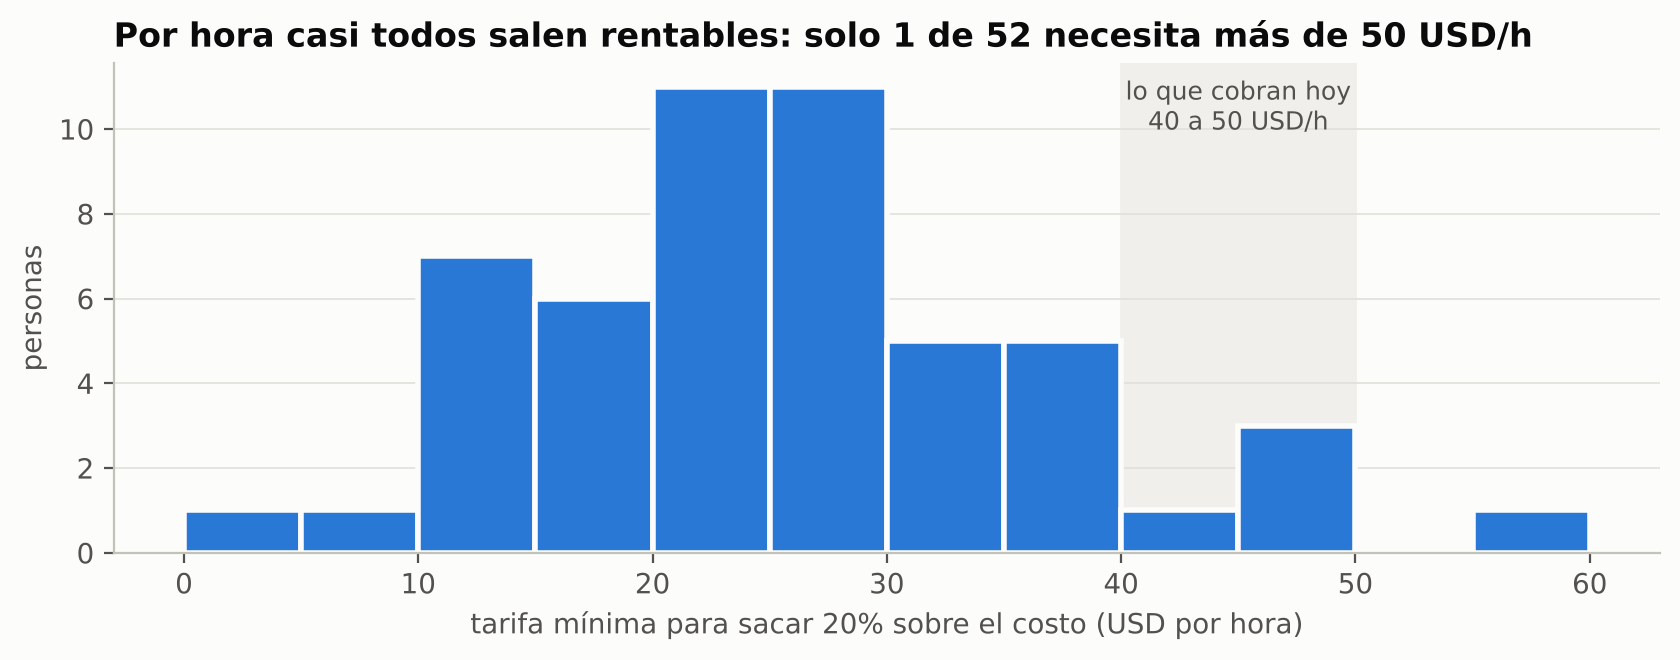

In [13]:
fact = col[activo & col['es_facturable'].eq(1) & col['tarifa_min_usd_20'].notna()]
tm = fact['tarifa_min_usd_20']
debajo, dentro, arriba = (tm < 40).sum(), tm.between(40, 50).sum(), (tm > 50).sum()
print(f'Facturables con costo: {len(fact)}')
print(f'  necesitan menos de 40 USD/h para sacar 20%: {debajo}')
print(f'  necesitan entre 40 y 50 USD/h: {dentro}')
print(f'  necesitan MÁS de 50 USD/h: {arriba}')
print(f'Tarifa mínima mediana: {tm.median():.1f} USD/h (rango {tm.min():.1f} a {tm.max():.1f})')

fig, ax = plt.subplots(figsize=(8.5, 3.4))
bins = np.arange(0, np.ceil(tm.max() / 5) * 5 + 5, 5)
ax.axvspan(40, 50, color='#f0efec', zorder=0)
ax.text(45, 0.97, 'lo que cobran hoy\n40 a 50 USD/h', transform=ax.get_xaxis_transform(), ha='center', va='top', fontsize=9, color=TINTA2)
ax.hist(tm, bins=bins, color=AZUL, edgecolor=FONDO, linewidth=2, zorder=2)
ax.set_xlabel('tarifa mínima para sacar 20% sobre el costo (USD por hora)')
ax.set_ylabel('personas')
ax.grid(axis='y', color=GRIS, lw=0.6); ax.set_axisbelow(True)
ax.set_title(f'Por hora casi todos salen rentables: solo {arriba} de {len(fact)} necesita más de 50 USD/h')
plt.tight_layout(); plt.savefig('tarifa_minima.png', dpi=160); plt.show()

**Entonces, ¿dónde se pierde el dinero?** Si por hora casi todos salen rentables, el problema tiene que estar en la gente que no está facturando. Aquí comparamos lo que dejan al mes los que sí están asignados contra lo que cuesta la banca, en los tres escenarios de tarifa. Lo hacemos dos veces: solo con la banca confirmada, y sumando a las 15 personas "por confirmar" por si resultan ser consultores.

In [14]:
costo_banca = col['costo_banca_mes'].sum()
costo_por_confirmar = col.loc[col['estado_banca'].eq('Por confirmar'), 'costo_mensual'].sum()
filas = []
for t in TARIFAS_USD:
    ganancia = (con_costo[f'ingreso_mes_{t}usd'] - con_costo['costo_asignacion_mes']).sum()
    filas.append({'tarifa USD/h': t, 'ganancia de los asignados': ganancia, 'costo de la banca': costo_banca,
                  'queda después de la banca': ganancia - costo_banca,
                  'queda si los por confirmar también son banca': ganancia - costo_banca - costo_por_confirmar,
                  '% de la ganancia que se come la banca': round(costo_banca / ganancia * 100, 1)})
alcanza = pd.DataFrame(filas).set_index('tarifa USD/h')
alcanza.round(0)

,ganancia de los asignados,costo de la banca,queda después de la banca,queda si los por confirmar también son banca,% de la ganancia que se come la banca
tarifa USD/h,,,,,
40,1603371.0,1363346.0,240026.0,-589018.0,85.0
45,2084929.0,1363346.0,721584.0,-107460.0,65.0
50,2566487.0,1363346.0,1203142.0,374098.0,53.0


## 11. Semáforo de confianza

A cada renglón de la tabla final le ponemos una calificación de qué tan completo está. Revisamos hasta 6 cosas: costo, puesto y habilidades, y si tiene asignación, también fecha de inicio, fecha de fin (o que sea indefinida) y rol capturado. **Verde** si cumple 80% o más, **amarillo** de 50 a 79% y **rojo** menos de 50%. En la columna `campos_por_revisar` dejamos escrito qué le falta.

La idea es que en el tablero el director sepa cuánto creerle a cada número. Preferimos eso a esconder el problema.

## 12. La tabla final

**¿Qué es cada renglón?** Un colaborador activo en una asignación. Si alguien no tiene proyecto aparece una vez con los campos del proyecto vacíos; así no se pierde la banca. El gerente que está en 2 proyectos aparece 2 veces, por eso agregamos `cuenta_persona` (1 solo en su primer renglón) para que en Tableau no se sume dos veces su sueldo.

Las bajas no entran a esta tabla. Se quedan en `colaboradores_limpio.csv` por si se quieren ver aparte.

In [15]:
pp = por_persona.reset_index()
base = (col[activo].merge(pp, left_on='uid', right_on='uid_colaborador', how='left').drop(columns='uid_colaborador'))
base[['n_habilidades', 'n_avanzado_experto']] = base[['n_habilidades', 'n_avanzado_experto']].fillna(0).astype(int)
base['captura_masiva'] = base['captura_masiva'].fillna(0).astype(int)

cols_asg = ['uid_colaborador', 'codigo_proyecto', 'codigo_cliente', 'cliente', 'proyecto', 'tipo_proyecto', 'rol_en_proyecto',
            'rol_origen', 'inicio', 'fin', 'inicio_conocido', 'es_indefinida', 'vigente', 'dias_para_liberarse',
            'ventana_liberacion', 'dedicacion', 'horas_mes', 'costo_asignacion_mes'] + \
           [f'ingreso_mes_{t}usd' for t in TARIFAS_USD] + [f'margen_{t}usd' for t in TARIFAS_USD] + ['fuera_de_periodo']
tabla = base.merge(asg[cols_asg], left_on='uid', right_on='uid_colaborador', how='left').drop(columns='uid_colaborador')
tabla = tabla.sort_values(['id', 'codigo_proyecto'], na_position='first').reset_index(drop=True)
tabla['cuenta_persona'] = (~tabla['id'].duplicated()).astype(int)

# Semáforo
tiene_asig = tabla['codigo_proyecto'].notna()
checks = {
    'costo': tabla['costo_faltante'].eq(0),
    'puesto': tabla['puesto'].notna(),
    'habilidades': tabla['n_habilidades'].gt(0),
    'fecha de inicio': tabla['inicio_conocido'].eq(1).where(tiene_asig),
    'fecha de fin': (tabla['fin'].notna() | tabla['es_indefinida'].eq(1)).where(tiene_asig),
    'rol': tabla['rol_origen'].eq('capturado').where(tiene_asig),
}
ch = pd.DataFrame(checks).astype(float)   # 1 = cumple, 0 = no cumple, vacío = no aplica
tabla['puntaje_confianza'] = (ch.sum(axis=1) / ch.notna().sum(axis=1)).round(2)
tabla['semaforo'] = np.select([tabla['puntaje_confianza'] >= 0.8, tabla['puntaje_confianza'] >= 0.5], ['Verde', 'Amarillo'], 'Rojo')
tabla['campos_por_revisar'] = ch.apply(lambda r: ', '.join(k for k, v in r.items() if v == 0), axis=1).replace('', np.nan)

renombre = {'id': 'id_colaborador', 'depto': 'departamento', 'inicio': 'inicio_asignacion', 'fin': 'fin_asignacion',
            'vigente': 'asignacion_vigente'}
orden = ['id_colaborador', 'nombre', 'tipo_colaborador', 'es_facturable', 'puesto', 'nivel', 'departamento', 'depto_origen',
         'ciudad', 'nomina', 'antiguedad_anios', 'baja_programada', 'cuenta_persona',
         'sueldo_total_integrado', 'costo_faltante', 'costo_mensual', 'costo_hora', 'tarifa_min_usd_20', 'tarifa_min_usd_30',
         'n_habilidades', 'n_avanzado_experto', 'tecnologia_principal', 'captura_masiva',
         'estado_banca', 'costo_banca_mes',
         'codigo_proyecto', 'codigo_cliente', 'cliente', 'proyecto', 'tipo_proyecto', 'rol_en_proyecto', 'rol_origen',
         'inicio_asignacion', 'fin_asignacion', 'es_indefinida', 'asignacion_vigente', 'dias_para_liberarse', 'ventana_liberacion',
         'dedicacion', 'horas_mes', 'costo_asignacion_mes'] + \
        [f'ingreso_mes_{t}usd' for t in TARIFAS_USD] + [f'margen_{t}usd' for t in TARIFAS_USD] + \
        ['fuera_de_periodo', 'puntaje_confianza', 'semaforo', 'campos_por_revisar']
tabla = tabla.rename(columns=renombre)[orden]
tabla['puesto'] = tabla['puesto'].fillna('Sin definir')
for c in ['costo_mensual', 'costo_hora', 'costo_banca_mes', 'costo_asignacion_mes'] + [f'ingreso_mes_{t}usd' for t in TARIFAS_USD]:
    tabla[c] = tabla[c].round(2)
for c in ['tarifa_min_usd_20', 'tarifa_min_usd_30'] + [f'margen_{t}usd' for t in TARIFAS_USD]:
    tabla[c] = tabla[c].round(3)
for c in ['es_indefinida', 'asignacion_vigente', 'fuera_de_periodo', 'dias_para_liberarse']:
    tabla[c] = tabla[c].astype('Int64')   # entero; vacío = la persona no tiene asignación

print('Tabla final:', tabla.shape[0], 'renglones x', tabla.shape[1], 'columnas |',
      tabla['id_colaborador'].nunique(), 'personas |', tabla['codigo_proyecto'].notna().sum(), 'asignaciones')
print('Semáforo:', tabla['semaforo'].value_counts().reindex(['Verde', 'Amarillo', 'Rojo']).to_dict())
print('Lo que más falta:', tabla['campos_por_revisar'].str.split(', ').explode().value_counts().to_dict())
tabla.head(8)

Tabla final: 76 renglones x 51 columnas | 75 personas | 31 asignaciones
Semáforo: {'Verde': 15, 'Amarillo': 51, 'Rojo': 10}
Lo que más falta: {'puesto': 29, 'rol': 29, 'habilidades': 28, 'fecha de inicio': 21, 'fecha de fin': 6, 'costo': 5}


,id_colaborador,nombre,tipo_colaborador,es_facturable,puesto,nivel,departamento,depto_origen,ciudad,nomina,antiguedad_anios,baja_programada,cuenta_persona,sueldo_total_integrado,costo_faltante,costo_mensual,costo_hora,tarifa_min_usd_20,tarifa_min_usd_30,n_habilidades,n_avanzado_experto,tecnologia_principal,captura_masiva,estado_banca,costo_banca_mes,codigo_proyecto,codigo_cliente,cliente,proyecto,tipo_proyecto,rol_en_proyecto,rol_origen,inicio_asignacion,fin_asignacion,es_indefinida,asignacion_vigente,dias_para_liberarse,ventana_liberacion,dedicacion,horas_mes,costo_asignacion_mes,ingreso_mes_40usd,ingreso_mes_45usd,ingreso_mes_50usd,margen_40usd,margen_45usd,margen_50usd,fuera_de_periodo,puntaje_confianza,semaforo,campos_por_revisar
0,OTC003,ABRAHAM PEREZ GIL,Sin definir,0,Sin definir,NaN,NaN,sin dato,Monterrey,XERES OT-SINDICATO,10.4,0,1,59730.70,0,71676.84,407.25,26.345,28.541,51,12,Oracle eBS,0,Por confirmar,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,<NA>,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,0.67,Amarillo,puesto
1,OTC004,ADRIANA PEREZ NAVARRETE,Consultor,1,CONSULTOR FUNCIONAL ORACLE CLOUD SENIOR,Senior,Operaciones y Soporte,capturado,Toluca,XERES OT-SINDICATO,4.3,0,1,59397.28,0,71276.74,404.98,26.198,28.381,0,0,NaN,0,Asignado,NaN,P003,C0001,METALSA,Asignación indefinida,Asignación de recursos,CONSULTOR FUNCIONAL ORACLE CLOUD SENIOR,puesto del colaborador,NaT,NaT,1,1,<NA>,Indefinida,1.0,176.0,71276.74,130592.0,146916.0,163240.0,0.832,1.061,1.290,0,0.50,Amarillo,"habilidades, fecha de inicio, rol"
2,OTC005,ALBERTO PEREZ BRETON,Consultor,1,CONSULTOR TÉCNICO JAVA SENIOR,Senior,Operaciones y Soporte,capturado,Monterrey,OTC-SINDICATO (SMR),10.8,0,1,67069.18,0,80483.02,457.29,29.582,32.047,8,2,Plataformas Tecnológicas,0,Asignado,NaN,P003,C0001,METALSA,Asignación indefinida,Asignación de recursos,CONSULTOR TÉCNICO JAVA SENIOR,puesto del colaborador,NaT,NaT,1,1,<NA>,Indefinida,1.0,176.0,80483.02,130592.0,146916.0,163240.0,0.623,0.825,1.028,0,0.67,Amarillo,"fecha de inicio, rol"
3,OTC006,ALBERTO ANTONIO PEREZ CHEE,Consultor (inferido),1,Sin definir,NaN,NaN,sin dato,Monterrey,SMR,10.7,0,1,65513.35,0,78616.02,446.68,28.896,31.304,26,14,Oracle eBS,0,Asignado,NaN,P002,C0001,METALSA,Soporte AMS Manufacta,Póliza de soporte,CONSULTOR FUNCIONAL ORACLE EBS SENIOR,capturado,2025-11-03,NaT,0,1,<NA>,Sin fecha de fin,1.0,176.0,78616.02,130592.0,146916.0,163240.0,0.661,0.869,1.076,0,0.67,Amarillo,"puesto, fecha de fin"
4,OTC009,ALLE JACOB PEREZ RANGEL,Consultor (inferido),1,Sin definir,NaN,NaN,sin dato,Monterrey,OTC-SINDICATO (SMR),4.0,0,1,109546.50,0,131455.80,746.91,48.317,52.344,9,2,Plataformas Tecnológicas,0,Asignado,NaN,P003,C0001,METALSA,Asignación indefinida,Asignación de recursos,NaN,sin dato,NaT,NaT,1,1,<NA>,Indefinida,1.0,176.0,131455.80,130592.0,146916.0,163240.0,-0.007,0.118,0.242,0,0.50,Amarillo,"puesto, fecha de inicio, rol"
5,OTC010,ANA LAURA PEREZ CARCAMO,Consultor,1,CONSULTOR FUNCIONAL ORACLE CLOUD Y EBS SENIOR,Senior,Operaciones y Soporte,capturado,Edo de México,OTC-SINDICATO (SMR),2.3,0,1,85666.88,0,102800.26,584.09,37.785,40.934,0,0,NaN,0,En banca,102800.26,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,<NA>,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,0.67,Amarillo,habilidades
6,OTC013,ARMANDINA PEREZ GARCÍA,Administrativo,0,ADMINISTRACIÓN FINANZAS SENIOR,Senior,Administración y Finanzas,catálogo de roles,Monterrey,ADMINISTRATIVA,1.8,0,1,NaN,1,NaN,NaN,NaN,NaN,0,0,NaN,0,No facturable,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaT,<NA>,<NA>,<NA>,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,0.33,Rojo,"costo, habilidades"
7,OTC014,CARLOS ADRIAN PEREZ VALDEZ,Consultor (inferido),1,Sin definir,NaN,NaN,sin dato,Monterrey,MAGNESON-SINDICATO,1.5,0,1,85511.26,0,102613.51,583.03,37.716,40.859,33,19,Oracle eBS,0,Asignado,NaN,P004,C0002,Grupo Daltile,Marazzi,Implementación,NaN,sin dato,2026-01-01,2027-01-01,0,1,46,31 a 60 días,1.0,176.0,102613.51,130592.0,146916.0,163240.0,0.273,0.432,0.591,1,0.67,Amarillo,"puesto, rol"


In [16]:
# Guardo la tabla final y las tablas limpias para Tableau
os.makedirs('salida', exist_ok=True)
tabla.to_csv('salida/tabla_acondicionada_ot.csv', index=False, encoding='utf-8-sig')
tabla.to_excel('salida/tabla_acondicionada_ot.xlsx', index=False)

col.drop(columns=['uid']).to_csv('salida/colaboradores_limpio.csv', index=False, encoding='utf-8-sig')
pro.drop(columns=['llave_original']).to_csv('salida/proyectos_limpio.csv', index=False, encoding='utf-8-sig')
asg.drop(columns=['llave_original', 'proyecto_val', 'rol']).to_csv('salida/asignaciones_limpio.csv', index=False, encoding='utf-8-sig')
mat.to_csv('salida/matriz_habilidades_limpio.csv', index=False, encoding='utf-8-sig')
hab.to_csv('salida/habilidades_limpio.csv', index=False, encoding='utf-8-sig')
cli.to_csv('salida/clientes_limpio.csv', index=False, encoding='utf-8-sig')
act.to_csv('salida/activos_limpio.csv', index=False, encoding='utf-8-sig')
aa.to_csv('salida/activos_asignaciones_limpio.csv', index=False, encoding='utf-8-sig')
sorted(os.listdir('salida'))

['activos_asignaciones_limpio.csv',
 'activos_limpio.csv',
 'asignaciones_limpio.csv',
 'clientes_limpio.csv',
 'colaboradores_limpio.csv',
 'habilidades_limpio.csv',
 'matriz_habilidades_limpio.csv',
 'proyectos_limpio.csv',
 'tabla_acondicionada_ot.csv',
 'tabla_acondicionada_ot.xlsx']

## 13. ¿Sí quedó limpio?

Aquí repetimos las revisiones de la etapa 2 sobre los datos limpios y comparamos contra los datos crudos. Lo que llega a cero se corrigió. Lo que no llega a cero no es que nos faltara limpiarlo: es información que no existe en la app y que solo OT puede capturar. Esa diferencia también es un resultado.

,problema,antes,después,estado
0,Fechas de relleno o imposibles,57,0,Resuelto
1,Textos con espacios de más,49,0,Resuelto
2,Habilidades de colaboradores que no existen,10,0,Resuelto
3,Habilidades de personas dadas de baja,253,0,Resuelto
4,País mal escrito,3,0,Resuelto
5,Asignaciones con tipo revuelto,23,0,Resuelto
6,Proyectos sin código propio,12,0,Resuelto
7,Activos sin departamento,64,31,Mejoró
8,Asignaciones sin rol,29,12,Mejoró
9,Activos con puesto PENDIENTE,29,29,Necesita que OT lo capture


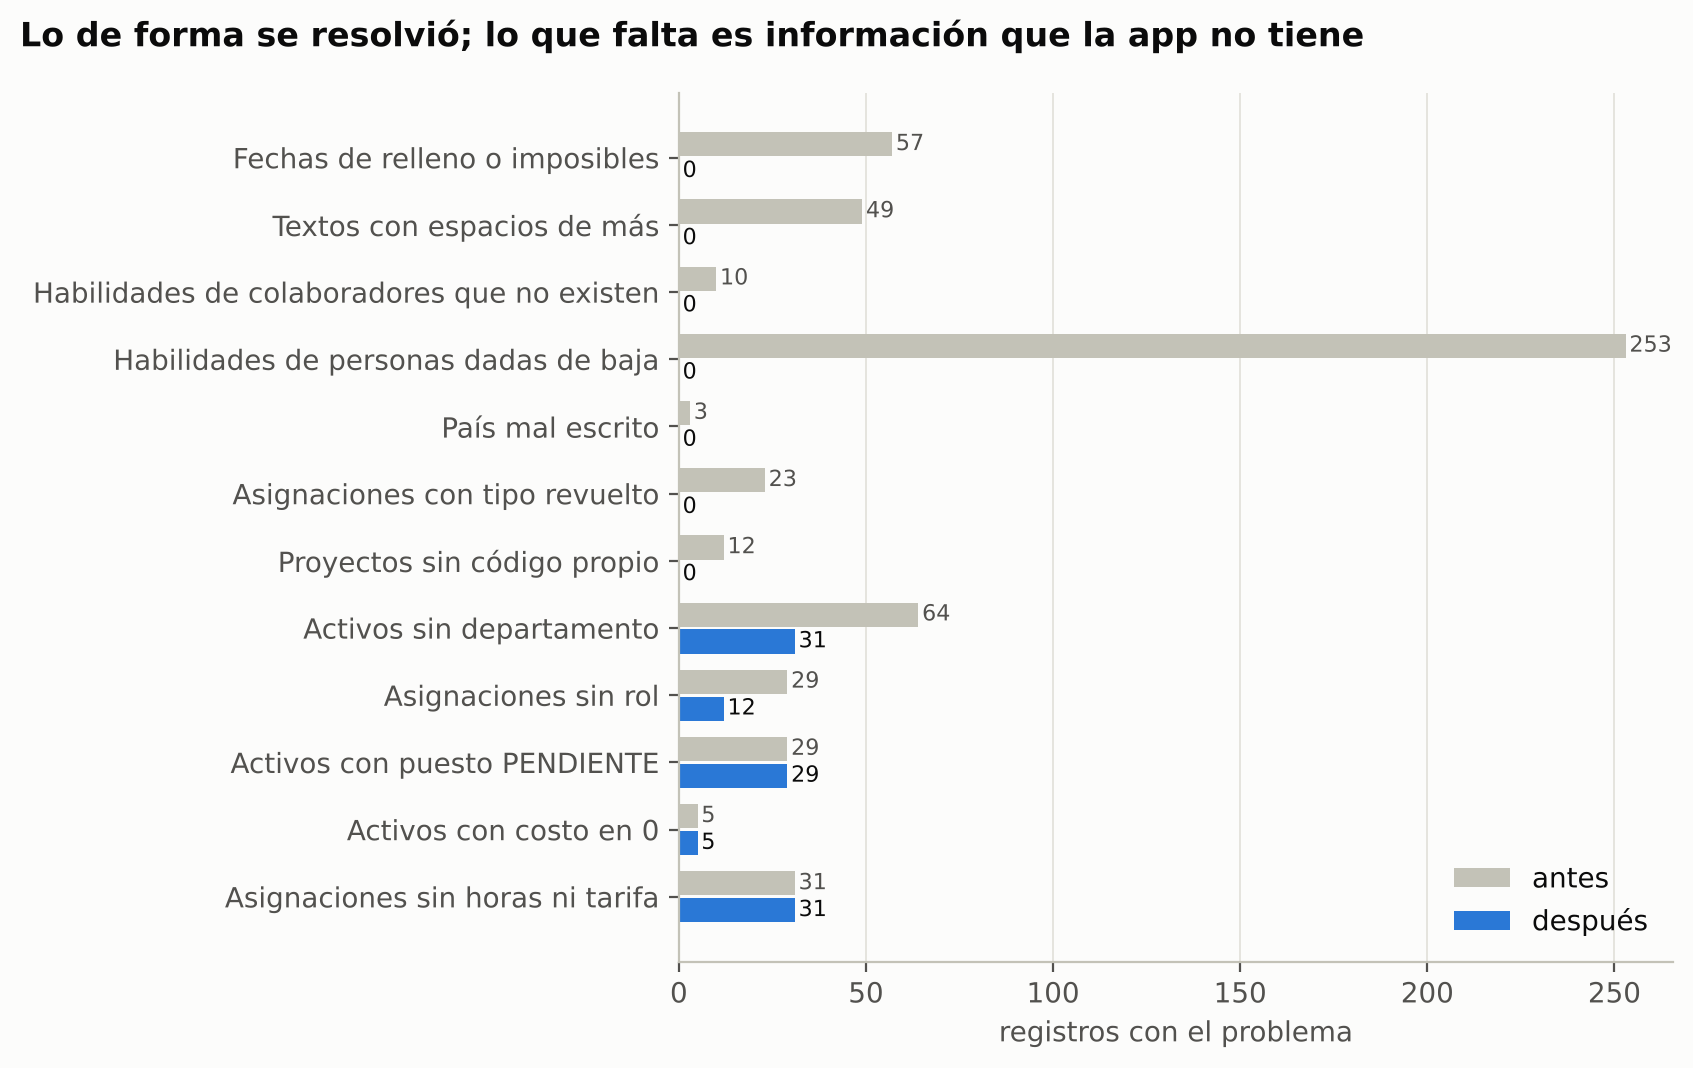

In [17]:
c_act = crudo['colaboradores']['estatus'].eq('Activo')
cr_mat = crudo['matriz_habilidades']
cr_asg = crudo['asignaciones']
espacios_despues = sum(
    int((t[c].dropna().astype(str) != t[c].dropna().astype(str).str.strip().str.replace(r'\s+', ' ', regex=True)).sum())
    for t in [col, roles, df['departamentos'], hab, cli, pro, act, aa] for c in t.columns
    if not pd.api.types.is_numeric_dtype(t[c]) and not pd.api.types.is_datetime64_any_dtype(t[c]))
asg_tipo_revuelto_despues = asg.merge(pro[['codigo_proyecto', 'tipo_proyecto']], on='codigo_proyecto', suffixes=('', '_p')) \
                               .pipe(lambda x: (x['tipo_proyecto'] != x['tipo_proyecto_p']).sum())

comparacion = pd.DataFrame([
    ['Fechas de relleno o imposibles', total_fechas, 0],
    ['Textos con espacios de más', total_espacios, espacios_despues],
    ['Habilidades de colaboradores que no existen', (~cr_mat['uid_colaborador'].isin(crudo['colaboradores']['uid'])).sum(), (~mat['uid_colaborador'].isin(col['uid'])).sum()],
    ['Habilidades de personas dadas de baja', de_baja.sum(), mat['uid_colaborador'].map(estatus).eq('Baja').sum()],
    ['País mal escrito', crudo['clientes']['pais'].notna().sum() - crudo['clientes']['pais'].eq('México').sum(), cli['pais'].notna().sum() - cli['pais'].eq('México').sum()],
    ['Asignaciones con tipo revuelto', revuelto.sum(), asg_tipo_revuelto_despues],
    ['Proyectos sin código propio', len(pro), pro['codigo_proyecto'].isna().sum()],
    ['Activos sin departamento', crudo['colaboradores'].loc[c_act, 'depto'].isna().sum(), col.loc[activo, 'depto'].isna().sum()],
    ['Asignaciones sin rol', cr_asg['rol'].eq('PENDIENTE').sum(), (asg['rol_origen'] == 'sin dato').sum()],
    ['Activos con puesto PENDIENTE', crudo['colaboradores'].loc[c_act, 'puesto'].eq('PENDIENTE').sum(), col.loc[activo, 'puesto'].isna().sum()],
    ['Activos con costo en 0', crudo['colaboradores'].loc[c_act, 'sueldo_total_integrado'].eq(0).sum(), col.loc[activo, 'sueldo_total_integrado'].isna().sum()],
    ['Asignaciones sin horas ni tarifa', len(cr_asg), len(cr_asg)],
], columns=['problema', 'antes', 'después'])
comparacion[['antes', 'después']] = comparacion[['antes', 'después']].astype(int)
comparacion['estado'] = np.select([comparacion['después'].eq(0), comparacion['después'].lt(comparacion['antes'])],
                                  ['Resuelto', 'Mejoró'], 'Necesita que OT lo capture')
display(comparacion)

orden_g = comparacion.iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 5.4))
y = np.arange(len(orden_g)); h = 0.36
ax.barh(y + h / 2 + 0.02, orden_g['antes'], height=h, color=GRIS_BARRA, label='antes')
ax.barh(y - h / 2 - 0.02, orden_g['después'], height=h, color=AZUL, label='después')
for i, (a_, d_) in enumerate(zip(orden_g['antes'], orden_g['después'])):
    ax.text(a_ + 1, i + h / 2 + 0.02, str(a_), va='center', fontsize=8, color=TINTA2)
    ax.text(d_ + 1, i - h / 2 - 0.02, str(d_), va='center', fontsize=8, color=TINTA)
ax.set_yticks(y); ax.set_yticklabels(orden_g['problema'])
ax.set_xlabel('registros con el problema'); ax.grid(axis='x', color=GRIS, lw=0.6); ax.set_axisbelow(True)
ax.legend(loc='lower right', frameon=False)
fig.suptitle('Lo de forma se resolvió; lo que falta es información que la app no tiene', x=0.01, ha='left', fontweight='bold', fontsize=12)
plt.tight_layout(); plt.savefig('antes_despues.png', dpi=160); plt.show()

También revisamos la tabla final con SQL, para asegurarnos de que no haya renglones repetidos ni bajas colados, y para ver que la banca y el margen por proyecto cuadren con lo que sacamos en pandas.

In [18]:
con = sqlite3.connect(':memory:')
t_sql = tabla.copy()
for c in ['inicio_asignacion', 'fin_asignacion']:
    t_sql[c] = t_sql[c].dt.strftime('%Y-%m-%d')
t_sql.to_sql('tabla', con, index=False)
sql = lambda q: pd.read_sql_query(q, con)

display(sql('''
SELECT COUNT(*) AS renglones,
       COUNT(DISTINCT id_colaborador) AS personas,
       SUM(cuenta_persona) AS personas_contadas,
       SUM(CASE WHEN codigo_proyecto IS NOT NULL THEN 1 ELSE 0 END) AS asignaciones,
       (SELECT COUNT(*) FROM (SELECT id_colaborador, codigo_proyecto FROM tabla WHERE codigo_proyecto IS NOT NULL
                              GROUP BY 1, 2 HAVING COUNT(*) > 1)) AS duplicados
FROM tabla
'''))

display(sql('''
SELECT estado_banca, COUNT(*) AS personas, ROUND(SUM(costo_mensual), 0) AS costo_mensual
FROM tabla WHERE cuenta_persona = 1
GROUP BY estado_banca ORDER BY costo_mensual DESC
'''))

display(sql('''
SELECT proyecto, COUNT(*) AS asignaciones,
       ROUND(SUM(costo_asignacion_mes), 0) AS costo_mes,
       ROUND((SUM(ingreso_mes_45usd) - SUM(costo_asignacion_mes)) * 100.0 / SUM(costo_asignacion_mes), 1) AS margen_45usd_pct
FROM tabla
WHERE codigo_proyecto IS NOT NULL AND costo_asignacion_mes IS NOT NULL
GROUP BY proyecto ORDER BY margen_45usd_pct
'''))

,renglones,personas,personas_contadas,asignaciones,duplicados
0,76,75,75,31,0


,estado_banca,personas,costo_mensual
0,Asignado,30,2309653.0
1,En banca,22,1363346.0
2,Por confirmar,15,829044.0
3,No facturable,8,200595.0


,proyecto,asignaciones,costo_mes,margen_45usd_pct
0,Asignación indefinida,18,1492356.0,69.8
1,Marazzi,3,176579.0,87.2
2,Soporte AMS Manufacta,5,382242.0,92.2
3,Migración eBs,5,197915.0,271.2


## 14. Metadata de la tabla final

Una línea por columna: qué es, de dónde sale y qué tan llena está. En **origen** usamos cinco tipos: *de la app* (viene tal cual), *limpio* (viene de la app pero lo arreglamos), *calculado* (sale de una fórmula con datos reales), *estimado* (sale de un supuesto) y *bandera* (marca de calidad).

In [19]:
DESCRIPCION = {
    'id_colaborador': ('Clave del colaborador en la app (OTC###)', 'de la app'),
    'nombre': ('Nombre del colaborador', 'de la app'),
    'tipo_colaborador': ('Consultor, Consultor (inferido), Gerente de proyectos, Administrativo, Familiar o Sin definir', 'calculado'),
    'es_facturable': ('1 si su trabajo se le cobra a un cliente', 'calculado'),
    'puesto': ('Puesto en OT; "Sin definir" si estaba en PENDIENTE', 'limpio'),
    'nivel': ('Nivel del puesto según el catálogo de roles', 'calculado'),
    'departamento': ('Área de OT', 'limpio'),
    'depto_origen': ('De dónde salió el departamento: capturado, catálogo de roles o sin dato', 'bandera'),
    'ciudad': ('Ciudad donde trabaja', 'de la app'),
    'nomina': ('Esquema de nómina', 'de la app'),
    'antiguedad_anios': ('Años en OT al corte', 'calculado'),
    'baja_programada': ('1 si está activo pero ya tiene fecha de baja', 'bandera'),
    'cuenta_persona': ('1 en el primer renglón de cada persona; usar para sumar nómina sin duplicar', 'calculado'),
    'sueldo_total_integrado': ('Sueldo mensual integrado en MXN; vacío si estaba en 0', 'limpio'),
    'costo_faltante': ('1 si el sueldo estaba en 0', 'bandera'),
    'costo_mensual': ('Sueldo integrado × 1.20 (MXN al mes)', 'calculado'),
    'costo_hora': ('Costo mensual / 176 (MXN por hora)', 'calculado'),
    'tarifa_min_usd_20': ('Tarifa mínima en USD/h para sacar 20% sobre el costo', 'calculado'),
    'tarifa_min_usd_30': ('Tarifa mínima en USD/h para sacar 30% sobre el costo', 'calculado'),
    'n_habilidades': ('Habilidades registradas en la matriz', 'calculado'),
    'n_avanzado_experto': ('Habilidades en nivel Avanzado o Experto', 'calculado'),
    'tecnologia_principal': ('Tecnología con más habilidades en Avanzado o Experto', 'calculado'),
    'captura_masiva': ('1 si tiene más de 20 habilidades todas en el mismo nivel', 'bandera'),
    'estado_banca': ('Asignado, En banca, Por confirmar o No facturable', 'calculado'),
    'costo_banca_mes': ('Costo mensual si está en banca (MXN)', 'calculado'),
    'codigo_proyecto': ('Clave nueva del proyecto (P###)', 'limpio'),
    'codigo_cliente': ('Clave del cliente (C####)', 'limpio'),
    'cliente': ('Nombre del cliente', 'limpio'),
    'proyecto': ('Nombre del proyecto', 'limpio'),
    'tipo_proyecto': ('Implementación, Póliza de soporte o Asignación de recursos (inferido del nombre)', 'estimado'),
    'rol_en_proyecto': ('Rol en la asignación; si estaba PENDIENTE, el puesto del colaborador', 'estimado'),
    'rol_origen': ('De dónde salió el rol: capturado, puesto del colaborador o sin dato', 'bandera'),
    'inicio_asignacion': ('Fecha de inicio; vacía si era de relleno', 'limpio'),
    'fin_asignacion': ('Fecha de fin', 'limpio'),
    'es_indefinida': ('1 si la asignación no tiene fin porque es indefinida', 'calculado'),
    'asignacion_vigente': ('1 si estaba en curso al 16 nov 2026', 'calculado'),
    'dias_para_liberarse': ('Días entre el corte y la fecha de fin', 'calculado'),
    'ventana_liberacion': ('0 a 30, 31 a 60, 61 a 90, más de 90 días, indefinida o sin fecha', 'calculado'),
    'dedicacion': ('Fracción de su tiempo en el proyecto (1.0 consultor, 0.25 gerente)', 'estimado'),
    'horas_mes': ('176 × dedicación', 'estimado'),
    'costo_asignacion_mes': ('Horas al mes × costo por hora (MXN)', 'estimado'),
    'fuera_de_periodo': ('1 si sus fechas se salen del periodo del proyecto', 'bandera'),
    'puntaje_confianza': ('Porcentaje de campos clave completos (0 a 1)', 'bandera'),
    'semaforo': ('Verde (≥0.8), Amarillo (0.5 a 0.79) o Rojo (<0.5)', 'bandera'),
    'campos_por_revisar': ('Qué campos clave le faltan', 'bandera'),
}
for t in TARIFAS_USD:
    DESCRIPCION[f'ingreso_mes_{t}usd'] = (f'Ingreso al mes si se cobra a {t} USD/h (MXN)', 'estimado')
    DESCRIPCION[f'margen_{t}usd'] = (f'(Ingreso − costo) / costo con {t} USD/h', 'estimado')

def tipo_dato(s):
    if pd.api.types.is_datetime64_any_dtype(s): return 'fecha'
    if pd.api.types.is_integer_dtype(s): return 'entero'
    if pd.api.types.is_numeric_dtype(s): return 'decimal'
    return 'texto'

metadata = pd.DataFrame([{'columna': c, 'tipo': tipo_dato(tabla[c]), 'descripción': DESCRIPCION[c][0],
                          'origen': DESCRIPCION[c][1], '% vacío': round(tabla[c].isna().mean() * 100, 1)}
                         for c in tabla.columns])
metadata.to_csv('salida/metadata_tabla_acondicionada.csv', index=False, encoding='utf-8-sig')
print(metadata['origen'].value_counts().to_dict())
metadata

{'calculado': 18, 'estimado': 11, 'limpio': 9, 'bandera': 9, 'de la app': 4}


,columna,tipo,descripción,origen,% vacío
0,id_colaborador,texto,Clave del colaborador en la app (OTC###),de la app,0.0
1,nombre,texto,Nombre del colaborador,de la app,0.0
2,tipo_colaborador,texto,"Consultor, Consultor (inferido), Gerente de pr...",calculado,0.0
3,es_facturable,entero,1 si su trabajo se le cobra a un cliente,calculado,0.0
4,puesto,texto,"Puesto en OT; ""Sin definir"" si estaba en PENDI...",limpio,0.0
5,nivel,texto,Nivel del puesto según el catálogo de roles,calculado,38.2
6,departamento,texto,Área de OT,limpio,40.8
7,depto_origen,texto,"De dónde salió el departamento: capturado, cat...",bandera,0.0
8,ciudad,texto,Ciudad donde trabaja,de la app,0.0
9,nomina,texto,Esquema de nómina,de la app,0.0


## 15. Bitácora completa

Todo lo que hicimos, en orden. La columna **resultado** dice si lo corregimos, lo eliminamos, lo estimamos o solo lo marcamos.

In [20]:
bit = pd.DataFrame(bitacora)
bit.to_csv('salida/bitacora_limpieza.csv', index=False, encoding='utf-8-sig')
print(bit['resultado'].value_counts().to_dict())
bit

{'Marcado': 12, 'Corregido': 9, 'Estimado': 5, 'Eliminado': 2}


,tabla,problema,qué hicimos,resultado,registros
0,todas,textos con espacios de más,"quitar espacios al inicio, al final y dobles",Corregido,49
1,todas,fechas de relleno o imposibles (antes del 2000),se dejan vacías y se marcan,Corregido,57
2,colaboradores,bajas con sueldo capturado,no suman a nómina ni banca (se filtran por est...,Marcado,12
3,colaboradores,bajas sin fecha de baja,se marcan para que OT capture la fecha,Marcado,18
4,colaboradores,activo con fecha de baja,se marca como baja programada,Marcado,1
5,colaboradores,activos con costo en 0,el costo queda vacío y se marca (no es costo r...,Marcado,5
6,colaboradores,activos sin departamento,se rellena con el departamento de su puesto en...,Estimado,33
7,colaboradores,puesto PENDIENTE pero con proyecto,se clasifica como consultor (inferido),Estimado,14
8,colaboradores,puesto PENDIENTE y sin proyecto,"queda ""Sin definir"" (banca por confirmar)",Marcado,15
9,colaboradores,familiares registrados como colaboradores,"tipo Familiar, no facturables",Marcado,2


## 16. Lo que nos llevamos

**Lo que sí se pudo arreglar.** Todo lo que era de forma: fechas de relleno, espacios de más, habilidades huérfanas o de gente que ya se fue, país mal escrito, tipos revueltos y proyectos sin código. Eso quedó en cero.

**Lo que no se pudo, y no se va a poder con código.** 29 activos sin puesto, 5 sin costo y ninguna asignación con horas ni tarifa. Eso ya no es limpieza, es captura, y le toca a OT. Por eso pusimos el semáforo: de los 76 renglones de la tabla final, solo 15 salen en verde. Lo que más falta es el puesto, el rol y las habilidades.

**La banca.** Confirmados hay 22 facturables sin proyecto que cuestan $1.36 millones al mes con la carga administrativa. Aparte hay 15 personas sin puesto ni proyecto ($829 mil al mes) que pueden ser banca o administrativos. Es lo primero que le preguntaríamos a OT, porque cambia bastante el número.

**Lo que más nos sorprendió.** Pensábamos que el problema eran las tarifas bajas, pero por hora casi todos salen rentables: la tarifa mínima mediana para sacar 20% es de 25 USD/h, y solo 1 de 52 facturables necesita más de 50. Lo que se come el dinero es la banca. Cobrando 40 USD/h, la banca se lleva el 85% de lo que dejan los asignados, y si las 15 personas "por confirmar" también son banca, OT pierde dinero cada mes. Eso conecta directo con el dolor del director: no le falta tarifa, le falta tener a su gente asignada.

**Ojo con los números de dinero.** Todo lo de ingreso y margen es un escenario: 40 a 50 USD/h, 176 horas al mes, tipo de cambio de 18.55 y 100% de dedicación. Además los datos son de prueba. Sirve para dimensionar el problema, no como dato real. Cuando OT capture tarifas y horas, solo hay que cambiar los supuestos de la sección 2 y todo se recalcula.

**Lo que sigue.** Terminar el tablero con `tabla_acondicionada_ot.csv` y pedirle a OT tres cosas: el puesto de las 15 personas por confirmar, las tarifas reales por rol y las horas de cada asignación.